# Chapter 4 - Regression and Prediction

**Practical Statistics for Data Scientists, 2nd ed.** - Peter Bruce, Andrew Bruce, and Peter Gedeck

This notebook demonstrates regression and prediction using original synthetic housing data. It covers simple and multiple linear models, validation, categories, interactions, intervals, diagnostics, and flexible regression.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. Create an analysis dataset

The response is `price_k` (thousands of currency units). The recipe deliberately includes noise, correlated predictors, an interaction, and a small nonlinear component. These let us practice fitting models and reading diagnostics rather than assuming the model is perfect.

In [2]:
n = 750
size_sqft = rng.normal(1650, 380, n).clip(650, 3400)
age = rng.gamma(2.4, 11, n).clip(0, 90)
neighborhood = rng.choice(["north", "central", "south"], n, p=[.3, .4, .3])
renovated = rng.binomial(1, .28, n)
bedrooms = np.round(1.2 + size_sqft/650 + rng.normal(0, .45, n)).clip(1, 6).astype(int)
area_effect = pd.Series(neighborhood).map({"north":45, "central":20, "south":-18}).to_numpy()
price_k = (65 + .165*size_sqft - .72*age + area_effect + 28*renovated + .025*renovated*size_sqft
           - .000025*(size_sqft-1650)**2 + rng.normal(0, 32, n))
homes = pd.DataFrame({"price_k":price_k, "size_sqft":size_sqft, "age":age, "bedrooms":bedrooms,
                      "neighborhood":neighborhood, "renovated":renovated})
homes.head(), homes.describe(include="all")

(   price_k  size_sqft     age  bedrooms neighborhood  renovated
 0  374.274   1765.792  22.915         4        north          0
 1  362.127   1254.806  10.163         2        north          0
 2  327.091   1935.171  64.260         4      central          0
 3  381.539   2007.415  11.059         4      central          0
 4  165.360    908.607  34.422         3      central          0,
         price_k  size_sqft      age  bedrooms neighborhood  renovated
 count   750.000    750.000  750.000   750.000          750    750.000
 unique      NaN        NaN      NaN       NaN            3        NaN
 top         NaN        NaN      NaN       NaN      central        NaN
 freq        NaN        NaN      NaN       NaN          302        NaN
 mean    346.179   1632.945   25.712     3.692          NaN      0.279
 std      84.472    373.702   16.338     0.789          NaN      0.449
 min      63.425    650.000    0.856     2.000          NaN      0.000
 25%     297.308   1374.763   13.948     

## 2. Simple linear regression

For one predictor, $\hat{Y}=b_0+b_1X$. The intercept is the fitted response at $X=0$ and the slope is the fitted response change for one additional X unit. A **residual** is observed minus fitted response. Ordinary least squares (OLS) minimizes the sum of squared residuals. Correlation makes variables symmetric; regression identifies a response to predict.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     65.0266      8.970      7.249      0.000      47.416      82.637
size_sqft      0.1722      0.005     32.151      0.000       0.162       0.183


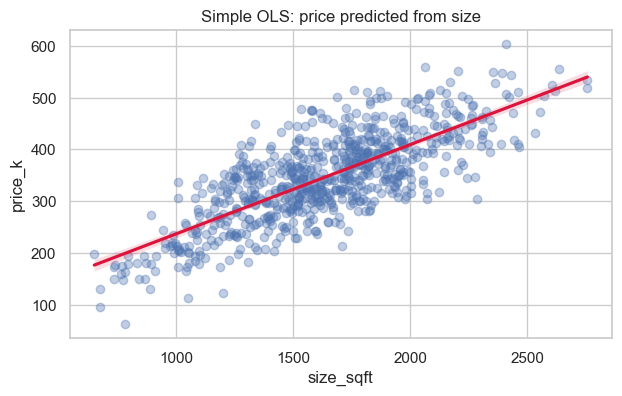

In [3]:
import statsmodels.formula.api as smf
simple_model = smf.ols("price_k ~ size_sqft", data=homes).fit()
print(simple_model.summary().tables[1])
fig, ax = plt.subplots(figsize=(7,4))
sns.regplot(data=homes, x="size_sqft", y="price_k", scatter_kws={"alpha":.35}, line_kws={"color":"crimson"}, ax=ax)
ax.set_title("Simple OLS: price predicted from size"); plt.show()

## 3. Multiple regression and predictive validation

Multiple regression estimates each coefficient conditional on the other included predictors. For prediction, assessment must use observations not used to fit the model. $R^2$ summarizes in-sample variance explained, while MAE and RMSE express prediction error in the target's units. Cross-validation repeats the held-out idea to obtain a more stable estimate.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
X, y = homes.drop(columns="price_k"), homes.price_k
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, random_state=42)
prep = ColumnTransformer([("numeric", SimpleImputer(strategy="median"), ["size_sqft","age","bedrooms","renovated"]),
                          ("category", OneHotEncoder(drop="first", handle_unknown="ignore"), ["neighborhood"])])
linear_pipe = Pipeline([("prepare", prep), ("model", LinearRegression())])
linear_pipe.fit(X_train, y_train); pred = linear_pipe.predict(X_test)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rmse = -cross_val_score(linear_pipe, X, y, cv=cv, scoring="neg_root_mean_squared_error")
pd.Series({"test MAE (thousand)":mean_absolute_error(y_test,pred), "test RMSE (thousand)":mean_squared_error(y_test,pred)**.5,
           "test R2":r2_score(y_test,pred), "5-fold mean RMSE":cv_rmse.mean(), "5-fold RMSE SD":cv_rmse.std()}).round(2)

test MAE (thousand)     25.42
test RMSE (thousand)    32.60
test R2                  0.86
5-fold mean RMSE        33.04
5-fold RMSE SD           2.34
dtype: float64

## 4. Factors, interactions, and intervals

Categorical variables become dummy indicators, with one reference level omitted to avoid perfect collinearity. An interaction changes the relation of one predictor at different values of another: here, size has an additional slope for renovated homes. A confidence interval describes uncertainty in the mean response; a prediction interval is wider because a new home's individual noise is included. Extrapolation outside observed ranges is risky.

In [5]:
multiple_model = smf.ols("price_k ~ size_sqft + age + bedrooms + C(neighborhood) + renovated + size_sqft:renovated", data=homes).fit()
print(multiple_model.summary().tables[1])
profile = pd.DataFrame({"size_sqft":[1200,1200,2000,2000], "age":[20]*4, "bedrooms":[3]*4,
                        "neighborhood":["central"]*4, "renovated":[0,1,0,1]})
intervals = multiple_model.get_prediction(profile).summary_frame(alpha=.05)
display(pd.concat([profile, intervals[["mean","mean_ci_lower","mean_ci_upper","obs_ci_lower","obs_ci_upper"]]], axis=1).round(1))
print(f"Observed size range: {homes.size_sqft.min():.0f} to {homes.size_sqft.max():.0f} sq ft")

                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   83.1376      7.032     11.824      0.000      69.334      96.942
C(neighborhood)[T.north]    24.7833      2.883      8.595      0.000      19.123      30.444
C(neighborhood)[T.south]   -41.6392      2.913    -14.295      0.000     -47.357     -35.921
size_sqft                    0.1688      0.005     33.310      0.000       0.159       0.179
age                         -0.8358      0.073    -11.373      0.000      -0.980      -0.691
bedrooms                    -1.8343      2.275     -0.806      0.420      -6.300       2.631
renovated                   30.8657     12.342      2.501      0.013       6.637      55.095
size_sqft:renovated          0.0253      0.007      3.432      0.001       0.011       0.040


,size_sqft,age,bedrooms,neighborhood,renovated,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,1200,20,3,central,0,263.5,258.5,268.5,199.2,327.9
1,1200,20,3,central,1,324.8,317.1,332.5,260.2,389.4
2,2000,20,3,central,0,398.6,391.4,405.7,334.0,463.1
3,2000,20,3,central,1,480.1,470.8,489.5,415.3,545.0


Observed size range: 650 to 2757 sq ft


## 5. Diagnostics

Residual patterns can reveal nonlinearity or nonconstant variance. Cook's distance flags observations that combine unusual predictors and large residuals. Variance inflation factor (VIF) flags correlated predictors, which can make individual coefficients unstable even when prediction is good. The Breusch-Pagan test is one formal check for heteroskedasticity.

VIFs:
 C(neighborhood)[T.north]     1.77
C(neighborhood)[T.south]     1.68
size_sqft                   43.53
age                          3.36
bedrooms                    44.98
renovated                   23.55
size_sqft:renovated         23.52
dtype: float64
Breusch-Pagan p-value: 0.6213


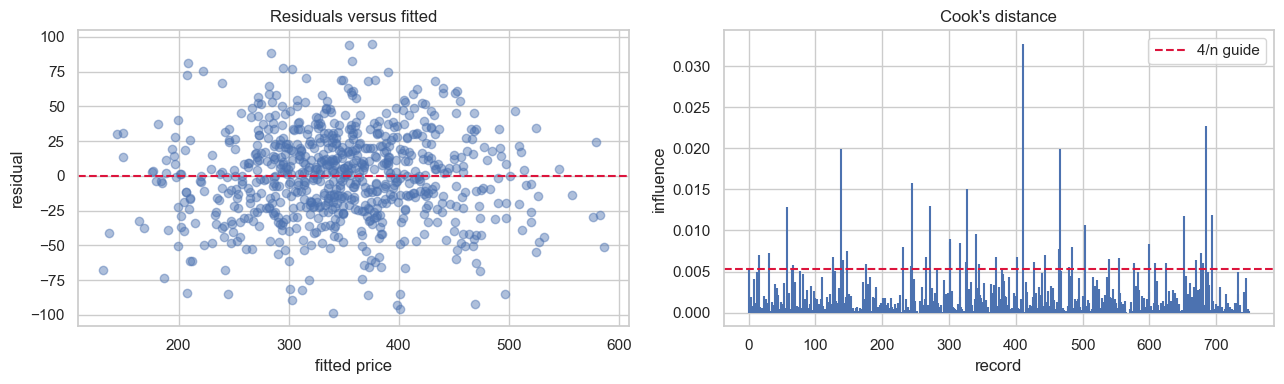

In [6]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
influence = OLSInfluence(multiple_model)
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].scatter(multiple_model.fittedvalues, multiple_model.resid, alpha=.45); axes[0].axhline(0, color="crimson", ls="--")
axes[0].set(title="Residuals versus fitted", xlabel="fitted price", ylabel="residual")
axes[1].stem(np.arange(n), influence.cooks_distance[0], markerfmt=" ", basefmt=" "); axes[1].axhline(4/n, color="crimson", ls="--", label="4/n guide")
axes[1].set(title="Cook's distance", xlabel="record", ylabel="influence"); axes[1].legend(); plt.tight_layout()
design = pd.DataFrame(multiple_model.model.exog, columns=multiple_model.model.exog_names).drop(columns="Intercept")
vif = pd.Series([variance_inflation_factor(design.values, i) for i in range(design.shape[1])], index=design.columns)
print("VIFs:\n", vif.round(2)); print(f"Breusch-Pagan p-value: {het_breuschpagan(multiple_model.resid, multiple_model.model.exog)[1]:.4f}")

## 6. Polynomial and spline regression

A polynomial adds global powers such as $X^2$. Splines fit connected low-degree pieces at knots, giving local flexibility. Flexible models can overfit, so use held-out validation to choose complexity rather than trusting visual fit alone.

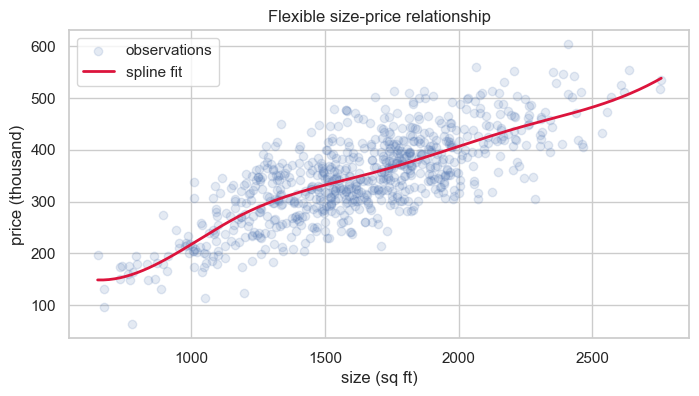

Linear AIC: 7366.5; polynomial AIC: 7356.5


In [7]:
from sklearn.preprocessing import SplineTransformer
poly_model = smf.ols("price_k ~ size_sqft + I(size_sqft**2) + age + bedrooms + C(neighborhood) + renovated", data=homes).fit()
spline = Pipeline([("basis", SplineTransformer(n_knots=5, degree=3, include_bias=False)), ("model", LinearRegression())])
spline.fit(homes[["size_sqft"]], homes.price_k)
grid = np.linspace(homes.size_sqft.min(), homes.size_sqft.max(), 200)
fig, ax = plt.subplots(figsize=(8,4)); ax.scatter(homes.size_sqft, homes.price_k, alpha=.15, label="observations")
ax.plot(grid, spline.predict(pd.DataFrame({"size_sqft":grid})), color="crimson", lw=2, label="spline fit")
ax.set(title="Flexible size-price relationship", xlabel="size (sq ft)", ylabel="price (thousand)"); ax.legend(); plt.show()
print(f"Linear AIC: {multiple_model.aic:.1f}; polynomial AIC: {poly_model.aic:.1f}")

## Chapter 4 summary

- Regression models a conditional relationship and predicts a numeric response.
- Test-set and cross-validated metrics are more credible than training performance.
- Categorical encodings, interactions, diagnostics, and interval type all affect interpretation.
- Regression coefficients show modelled association, not causation by themselves; avoid extrapolation.

**Reference:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.), Chapter 4. Concepts and organization informed by the supplied PDF; all prose, code, and synthetic data here are original.